<a href="https://colab.research.google.com/github/SaraEstilaei/DigiSmart_Assistant/blob/P3%2F-Baseline(TF-IDF)/Baseline_recommendation_status.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<div dir="rtl">

# Part 3 — Baseline: پیش‌بینی `recommendation_status` (TF-IDF + مدل‌های خطی)

**هدف:** از روی *متن* یک نظر، یکی از سه کلاس `recommended` / `not_recommended` / `no_idea` را پیش‌بینی کنیم. معیار اصلی: **Macro F1**.

**پروتکل:**
1. ورودی فقط متن است: `title + body + advantages + disadvantages` (ستون `rate` و بقیه‌ی ستون‌ها وارد مدل نمی‌شوند).
2. تقسیم داده **بر اساس `product_id`** (`StratifiedGroupKFold`) تا هیچ محصولی هم در train و هم در test نباشد، با حفظ نسبت کلاس‌ها.
3. هیچ متن یکسانی در دو بخش مختلف نیست (حذف هم‌پوشانی متنی از train/val نسبت به test).
4. همه‌ی انتخاب‌ها (نوع ویژگی، `C`، مدل، bias کلاس‌ها) فقط روی **validation**؛ **test فقط یک‌بار** برای مدل نهایی.
5. داده‌ی Split  شده ذخیره می‌شود تا ParsBERT / FaBERT / XLM-R دقیقاً روی همان داده اجرا شوند.

**خروجی‌ها:** جدول مقایسه‌ی مدل‌ها، Macro F1 تست با بازه‌ی اطمینان، confusion matrix، تحلیل خطا، تابع `predict_recommendation(text)`، فایل Split.
</div>


In [1]:
import os, sys, re, json, time, random, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import zipfile
import gdown

try:
    from IPython.display import display
except Exception:
    display = print

warnings.filterwarnings("ignore", category=FutureWarning)

# ------------------------- Config -------------------------

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

pd.set_option("display.max_columns", 60)
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 220)


DATA_SOURCE = "gdown"          # "gdown" | "drive" | "local"
BASELINE_URL = "https://drive.google.com/uc?id=1yfIKMZHfBkJ582ym35vauwQLuCQ8BWz-"

PERSIST_TO_DRIVE = True        # in Colab: save outputs to Google Drive so they survive runtime resets
QUICK = False                  # True => tiny grids, for a fast smoke test only
STRICT_TEXT_DEDUP = True       # no identical text may appear in two different splits
N_FOLDS = 7                    # 1 fold -> test (~14%), 1 fold -> val (~14%), 5 folds -> train (~72%)
N_BOOT = 1000                  # bootstrap resamples (clustered by product) for the test CI
RUN_LEARNING_CURVE = True

# ------------------------- Environment -------------------------

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB and PERSIST_TO_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    WORK_DIR = Path("/content/drive/MyDrive/QBC13_final/baseline")
else:
    WORK_DIR = Path("qbc13_baseline")

RAW_DIR, SRC_DIR, OUT_DIR, MODEL_DIR, SPLIT_DIR = (
    WORK_DIR / d
    for d in ("raw", "src", "outputs", "models", "splits")
)

for d in (RAW_DIR, SRC_DIR, OUT_DIR, MODEL_DIR, SPLIT_DIR):
    d.mkdir(parents=True, exist_ok=True)

# ------------------------- Download -------------------------

DOWNLOAD_PATH = RAW_DIR / "baseline_data"

if not DOWNLOAD_PATH.exists():
    gdown.download(BASELINE_URL, str(DOWNLOAD_PATH), quiet=False)

if not DOWNLOAD_PATH.exists() or DOWNLOAD_PATH.stat().st_size == 0:
    raise RuntimeError("Download failed. Check Google Drive sharing permissions.")

# ------------------------- Extract if ZIP -------------------------

EXTRACT_DIR = RAW_DIR / "extracted"

if zipfile.is_zipfile(DOWNLOAD_PATH):
    EXTRACT_DIR.mkdir(parents=True, exist_ok=True)

    with zipfile.ZipFile(DOWNLOAD_PATH, "r") as zip_ref:
        zip_ref.extractall(EXTRACT_DIR)

    print("ZIP extracted successfully.")
    print("Extracted files:", list(EXTRACT_DIR.rglob("*")))

else:
    print("Downloaded file is not a ZIP archive.")
    print("File path:", DOWNLOAD_PATH)

print("WORK_DIR =", WORK_DIR.resolve())

Mounted at /content/drive


Downloading...
From: https://drive.google.com/uc?id=1yfIKMZHfBkJ582ym35vauwQLuCQ8BWz-
To: /content/drive/MyDrive/QBC13_final/baseline/raw/baseline_data
100%|██████████| 2.29M/2.29M [00:00<00:00, 124MB/s]

Downloaded file is not a ZIP archive.
File path: /content/drive/MyDrive/QBC13_final/baseline/raw/baseline_data
WORK_DIR = /content/drive/MyDrive/QBC13_final/baseline


## ۱) بارگذاری داده

In [2]:
# ------------------------- Load Baseline Data -------------------------

c_path = DOWNLOAD_PATH

# Check Parquet file validity
with open(c_path, "rb") as f:
    if f.read(4) != b"PAR1":
        raise RuntimeError("Invalid Parquet file or download error.")

# Load dataset
comments = pd.read_parquet(c_path)

print("Dataset path:", c_path)
print("comments:", comments.shape)

display(comments.head())

Dataset path: /content/drive/MyDrive/QBC13_final/baseline/raw/baseline_data
comments: (8000, 12)


,id,product_id,rate,created_date,body_persian_ratio,title,body,advantages,disadvantages,recommendation_status,likes,dislikes
0,14144758,1075274,5.00,2020-11-30,0.818,هری پاتر,عالیه مخصوصا طرحش عکس مجموعه هری پاترم رو میزارم اگه خوشتون اومد لطفا لایک کنید که نظرم موندگار بشه,None,None,recommended,1136,8
1,29774764,6850623,4.00,2022-01-07,0.799,این مجله تبلیغاتی است و بایستی رایگان دست مشتریهای ثابت میرسید,این مجله را باید دیجی کالا باید رایگان به مشتری های ثابت و قدیمی ارسال می کرد تا اطلاعات مشتری کامل تر بشود ولی متأس...,None,None,recommended,414,6
2,16583783,268428,2.75,2021-01-28,0.787,در صورت قصد خرید مطالعه شود,محصول با کیفیت و کار بردی‌ایه ، بسته بندی خاصی نداره یه برگه کاغذی توشه که یه سری توضیحات در مورد محصول نوشته شده و ...,None,None,recommended,394,2
3,35312390,2880389,4.00,2022-05-29,0.766,حتمن دقت کنید که:,این سه تا مدل سوت نجات رو گرفتم هر کدومشون یه مزیت خاص بخودش رو داره که سعی میکنم خلاصه بهتون بگم شاید تو خریدش کمکت...,قیمت مناسب | صدای بلند | بدنه آلومینیوم سبک,None,recommended,375,6
4,11137579,1545574,4.00,2020-08-18,0.762,طریقه استفاده از دستگاه,بنده این دستگاه رو تهیه کردم البته مدل سه هندپیس رو. اشرکت رایان مدیکا به هیچ عنوان پاسخگو نبودن. ازینرو تحقیق زیادی...,None,None,no_idea,372,0


<div dir="rtl">

## ۲) ماژول پیش‌پردازش متن فارسی (یک منبع واحد برای همه‌ی نوت‌بوک‌ها)
این سلول فایل `src/persian_text.py` را می‌نویسد. بقیه‌ی اعضای تیم (و نوت‌بوک ParsBERT) می‌توانند همین فایل را import کنند تا **همه‌ی مدل‌ها یک پیش‌پردازش یکسان** داشته باشند. :>

تصمیم‌های پیش‌پردازش:
- `NFKC` + یکسان‌سازی حروف عربی/فارسی (`ي به ی`, `ك به ک`, ...) و ارقام فارسی/عربی به لاتین
- حذف اعراب، کشیده (ـ) و کاراکترهای نامرئی؛ حذف URL
- حروف تکراری (۳ بار یا بیشتر) → یک بار (`عاااالی به عالی`)؛ ارقام دست‌نخورده (تا `1000000` خراب نشود)
- **نیم‌فاصله در متن ذخیره‌شده حفظ می‌شود** (برای توکنایزر BERT مفید است) ولی فقط برای TF-IDF به فاصله تبدیل می‌شود
- ایموجی‌ها حذف نمی‌شوند (ممکن است سیگنال احساسی باشند)
</div>


In [3]:
PERSIAN_TEXT_SRC = r'''
import ast
import re
import unicodedata

import numpy as np

LABELS = ["recommended", "not_recommended", "no_idea"]
ZWNJ = "\u200c"

_CHAR_MAP = str.maketrans({"ي": "ی", "ى": "ی", "ك": "ک", "ة": "ه", "أ": "ا", "إ": "ا", "ٱ": "ا"})
_DIGIT_MAP = str.maketrans("۰۱۲۳۴۵۶۷۸۹٠١٢٣٤٥٦٧٨٩", "01234567890123456789")
_DIACRITICS = re.compile("[\u064b-\u065f\u0670\u0640]")
_INVISIBLE = re.compile("[\u200b\u200d\u200e\u200f\u202a-\u202e\u2066-\u2069\ufeff]")
_URL = re.compile(r"(https?://\S+|www\.\S+)")
_REPEAT = re.compile(r"([^\d\s])\1{2,}")
_SPACES = re.compile(r"\s+")
_NULLS = {"none", "nan", "null", "<na>", "nat", "[]"}


def normalize_label(x):
    if x is None:
        return None
    s = str(x).strip().lower().replace(" ", "_").replace("-", "_")
    return s if s in LABELS else None


def to_str(x):
    if x is None:
        return ""
    if isinstance(x, (list, tuple, set, np.ndarray)):
        parts = [to_str(i) for i in x]
        return " ، ".join(p for p in parts if p)
    if isinstance(x, float) and x != x:
        return ""
    s = str(x).strip()
    if s.lower() in _NULLS:
        return ""
    if s.startswith("[") and s.endswith("]"):
        try:
            v = ast.literal_eval(s)
            if isinstance(v, (list, tuple)):
                return to_str(list(v))
        except Exception:
            pass
    return s


def clean_text(x):
    s = to_str(x)
    if not s:
        return ""
    s = unicodedata.normalize("NFKC", s)
    s = s.translate(_CHAR_MAP).translate(_DIGIT_MAP)
    s = _URL.sub(" ", s)
    s = _DIACRITICS.sub("", s)
    s = _INVISIBLE.sub("", s)
    s = _REPEAT.sub(r"\1", s)
    s = _SPACES.sub(" ", s).strip()
    return s


def build_text(title=None, body=None, advantages=None, disadvantages=None):
    t, b = clean_text(title), clean_text(body)
    a, d = clean_text(advantages), clean_text(disadvantages)
    parts = []
    if t:
        parts.append(t)
    if b and b != t:
        parts.append(b)
    if a:
        parts.append("مزایا: " + a)
    if d:
        parts.append("معایب: " + d)
    return " . ".join(parts)


def tfidf_preprocess(s):
    # used only by TF-IDF: lowercase latin + ZWNJ -> space (so "می‌خوام" == "می خوام")
    return s.lower().replace(ZWNJ, " ")
'''
(SRC_DIR / "persian_text.py").write_text(PERSIAN_TEXT_SRC, encoding="utf-8")

if str(SRC_DIR.resolve()) not in sys.path:
    sys.path.insert(0, str(SRC_DIR.resolve()))
import importlib, persian_text
importlib.reload(persian_text)
from persian_text import LABELS, normalize_label, to_str, clean_text, build_text, tfidf_preprocess

# ---- unit tests ----
assert clean_text("عاااالی!!!") == "عالی!"
assert clean_text("كتاب ي خوب") == "کتاب ی خوب"
assert clean_text("قیمت ۱۰۰۰۰۰۰ تومان") == "قیمت 1000000 تومان"
assert clean_text(None) == "" and clean_text(float("nan")) == "" and clean_text("None") == ""
assert clean_text(["خوب", "ارزان"]) == "خوب ، ارزان"
assert clean_text("سلام   \n  دنیا") == "سلام دنیا"
assert tfidf_preprocess("می\u200cخوام") == "می خوام"
assert build_text("عالی", "عالی", None, "گرون") == "عالی . معایب: گرون"
print("persian_text.py written and unit tests passed ->", SRC_DIR / "persian_text.py")

persian_text.py written and unit tests passed -> /content/drive/MyDrive/QBC13_final/baseline/src/persian_text.py


<div dir="rtl">

## ۳) ممیزی داده (Data Audit)
قبل از هر تصمیمی، داده را می‌بینیم. خروجی این سلول‌ها مستقیماً به بخش «کیفیت داده» گزارش می‌رود.

</div>


In [4]:
print("Columns:", list(comments.columns))
display(comments.head(3))
print()
print("Dtypes:"); print(comments.dtypes.to_string())

nulls = comments.isna().mean().mul(100).round(2).sort_values(ascending=False)
print("\nNull % per column (only >0):")
display(nulls[nulls > 0].to_frame("null_%"))

print("Is 'id' unique? ", comments["id"].is_unique if "id" in comments else "no id column")
print("Raw recommendation_status values:")
display(comments["recommendation_status"].value_counts(dropna=False).to_frame("count")
        .assign(pct=lambda d: (d["count"] / d["count"].sum() * 100).round(2)))

Columns: ['id', 'product_id', 'rate', 'created_date', 'body_persian_ratio', 'title', 'body', 'advantages', 'disadvantages', 'recommendation_status', 'likes', 'dislikes']


,id,product_id,rate,created_date,body_persian_ratio,title,body,advantages,disadvantages,recommendation_status,likes,dislikes
0,14144758,1075274,5.00,2020-11-30,0.818,هری پاتر,عالیه مخصوصا طرحش عکس مجموعه هری پاترم رو میزارم اگه خوشتون اومد لطفا لایک کنید که نظرم موندگار بشه,None,None,recommended,1136,8
1,29774764,6850623,4.00,2022-01-07,0.799,این مجله تبلیغاتی است و بایستی رایگان دست مشتریهای ثابت میرسید,این مجله را باید دیجی کالا باید رایگان به مشتری های ثابت و قدیمی ارسال می کرد تا اطلاعات مشتری کامل تر بشود ولی متأس...,None,None,recommended,414,6
2,16583783,268428,2.75,2021-01-28,0.787,در صورت قصد خرید مطالعه شود,محصول با کیفیت و کار بردی‌ایه ، بسته بندی خاصی نداره یه برگه کاغذی توشه که یه سری توضیحات در مورد محصول نوشته شده و ...,None,None,recommended,394,2



Dtypes:
id                                int64
product_id                        int64
rate                            float64
created_date             datetime64[ns]
body_persian_ratio              float32
title                            object
body                             object
advantages                       object
disadvantages                    object
recommendation_status            object
likes                             int64
dislikes                          int64

Null % per column (only >0):


,null_%
disadvantages,77.65
advantages,63.36
rate,11.79


Is 'id' unique?  True
Raw recommendation_status values:


,count,pct
recommendation_status,,
recommended,6351,79.39
not_recommended,847,10.59
no_idea,802,10.02


In [5]:
# What do the text fields look like? (types / samples)
for col in ["title", "body", "advantages", "disadvantages"]:
    if col in comments.columns:
        nn = comments[col].dropna()
        print(f"--- {col}: non-null={len(nn)} ({len(nn)/len(comments)*100:.1f}%), python types={nn.map(type).value_counts().to_dict()}")
        print(nn.head(3).tolist())
    else:
        print(f"--- {col}: NOT in columns")

--- title: non-null=8000 (100.0%), python types={<class 'str'>: 8000}
['هری پاتر', 'این مجله تبلیغاتی است و بایستی رایگان دست مشتریهای ثابت میرسید', 'در صورت قصد خرید مطالعه شود']
--- body: non-null=8000 (100.0%), python types={<class 'str'>: 8000}
['عالیه مخصوصا طرحش عکس مجموعه هری پاترم رو میزارم اگه خوشتون اومد لطفا لایک کنید که نظرم موندگار بشه', 'این مجله را باید دیجی کالا باید رایگان به مشتری های ثابت و قدیمی ارسال می کرد تا اطلاعات مشتری کامل تر بشود ولی متأسفانه فروشی ارائه می شود', 'محصول با کیفیت و کار بردی\u200cایه ، بسته بندی خاصی نداره یه برگه کاغذی توشه که یه سری توضیحات در مورد محصول نوشته شده و محصول توی یه کاور پلاستیکیه معمولی ارسال شده ، توی چند هفته ای که خریدمش چندین بار ازش استفاده کردم ، کافیه 1 دقیقه الی نهایت یک دقیقه و نیم توی ماکروفر قرارش بدید ، بعد برش دارید و یه کم بمالیدش تا تمام مواد داخلش پخش بشه ، حالا آمادست برای استفاده ، حدود نیم ساعت گرمای مطلوبی رو بهتون میده و اروم اروم شروع به از دست دادن دما میکنه ، مواد بکار رفته داخلش حالت ژلاتینی داره و روی 

rate x recommendation_status (row-normalised %):


recommendation_status,no_idea,not_recommended,recommended
rate,,,
0.05,0.0,100.0,0.0
0.20,0.0,100.0,0.0
0.25,0.0,25.0,75.0
0.30,0.0,100.0,0.0
0.40,0.0,100.0,0.0
...,...,...,...
4.75,0.0,0.0,100.0
4.80,0.0,0.0,100.0
4.85,0.0,0.0,100.0



body length (words) per class:


,count,mean,std,min,25%,50%,75%,max
recommendation_status,,,,,,,,
no_idea,802.0,68.1,78.5,2.0,22.0,42.0,85.0,853.0
not_recommended,847.0,59.2,60.2,2.0,22.0,41.0,76.0,623.0
recommended,6351.0,50.3,74.3,1.0,10.0,24.0,56.0,862.0



Top-10 most frequent bodies and their label distribution:


recommendation_status,recommended
body,
خوب بود,7
خیلی خوب بود,6
خیلی عالی بود,6
عالی,13
عالی بود,6
عالی و فوق العاده و کاملا راضیم این کتاب امروز سالم و بسته بندی عالی به دستم رسید. کاغذ سفید مرغوب خارجی درجه یک داره. فونت و صفحه آرایی قوی و خوبی داره چند ص از کتاب رو مطالعه کردم. ترجمه فوق العاده داره. نسبت به تخفیفی که خورده فتوکپی بخوایم بگیریم ارزونتر در میاد. جلد مقوایی با کیفیت داره و چاپ و طراحی ظاهریش عالیه. چاپ داخلش تمیز و یکدست و بدون ایراده. کتاب سبک وزن هست و دست رو خسته نمیکنه. از خریدم کامل راضی هستم. برای کادو دادن از همه لحاظ مناسب و شایسته هستش. جزو معدود خریدهایی هست که رضایت 100 درصد دارم. از دیجی کالا هم به خاطر تخفیف های خوب و ارسال به موقع و حمایت 100 درصدی از قشر کتابخون تو این وضعیت اقتصادی تشکر میکنم.,5
عالیه,6
عالیی,9
مجموعه عاشقانه‌های کلاسیک نشر افق یک مجموعه رمان هفده جلدیه که علاوه بر داستان بسیار زیبا از نویسندگان برتر دنیا دارای طراحی جلد منحصر به فردیه که آدمو شیفته خودش میکنه ؛) به شدت به عاشقان کتاب پیشنهاد میکنم این مجموعه زیبا رو خریداری کنید با تخفیف‌های خوب دیجی کالا. عکس این مجموعه را آپلود کردم مشاهده کنید.,5


Exact-duplicate body rate: 1.55%

comments per product:


,count,mean,std,min,25%,50%,75%,max
value,5207.0,1.5,2.0,1.0,1.0,1.0,1.0,50.0


share of comments from top-1% products: 10.9%

created_date range: 2016-07-23 00:00:00 -> 2023-10-09 00:00:00
comments with Persian ratio < 0.3: 0.01%


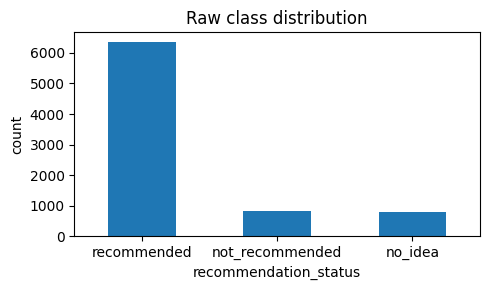

In [6]:
# Relationship between label and rate (diagnostic only; rate is NOT a model feature)
if "rate" in comments.columns:
    print("rate x recommendation_status (row-normalised %):")
    display((pd.crosstab(comments["rate"], comments["recommendation_status"], normalize="index") * 100).round(1))

# Text length per class
tmp = comments.copy()
tmp["n_words"] = tmp["body"].map(to_str).str.split().str.len()
print("\nbody length (words) per class:")
display(tmp.groupby("recommendation_status")["n_words"].describe().round(1))

# Most frequent bodies (generic phrases are a leakage / duplication risk)
top_bodies = tmp["body"].map(clean_text).value_counts().head(10).index
print("\nTop-10 most frequent bodies and their label distribution:")
display(pd.crosstab(tmp["body"].map(clean_text)[tmp["body"].map(clean_text).isin(top_bodies)],
                    tmp["recommendation_status"]))
print("Exact-duplicate body rate: %.2f%%" % (tmp["body"].map(clean_text).duplicated().mean() * 100))

# Product groups (why we must split by product)
vc = comments["product_id"].value_counts()
print("\ncomments per product:"); display(vc.describe().round(1).to_frame("value").T)
print("share of comments from top-1%% products: %.1f%%" % (vc.head(max(1, int(len(vc) * 0.01))).sum() / vc.sum() * 100))

if "created_date" in comments.columns:
    d = pd.to_datetime(comments["created_date"], errors="coerce")
    print("\ncreated_date range:", d.min(), "->", d.max())
if "body_persian_ratio" in comments.columns:
    print("comments with Persian ratio < 0.3: %.2f%%" % ((comments["body_persian_ratio"] < 0.3).mean() * 100))

# Class distribution plot
ax = comments["recommendation_status"].value_counts().plot.bar(rot=0, figsize=(5, 3))
ax.set_title("Raw class distribution"); ax.set_ylabel("count"); plt.tight_layout(); plt.show()

<div dir="rtl">

## ۴) پاک‌سازی و ساخت متن ورودی
تصمیم‌ها (هر خط یک ردیف در جدول لاگ ثبت می‌شود):
- برچسب نامعتبر/خالی حذف می‌شود.
- متن = `title . body . مزایا: ... . معایب: ...` (فقط فیلدهای غیرخالی).
- متن خالی بعد از پاک‌سازی حذف می‌شود.
- تکراری‌های دقیق **داخل یک محصول** (همان `product_id` + همان متن + همان برچسب، مثل ثبت دوباره‌ی یک نظر) حذف می‌شود. تکراری‌های بین محصولات (مثل «عالی») نگه داشته می‌شوند چون در دنیای واقعی هم هستند؛ هم‌پوشانی بین splitها در مرحله‌ی بعد کنترل می‌شود.
- نظرهای کوتاه و غیرفارسی **حذف نمی‌شوند** (فقط گزارش می‌شوند) تا Test توزیع طبیعی داشته باشد.
</div>


In [7]:
df = comments.copy()
log = []
def step(name, d):
    log.append({"step": name, "rows": len(d), "products": d["product_id"].nunique()})

step("raw", df)

# --- labels
df["label"] = df["recommendation_status"].map(normalize_label)
n_bad = df["label"].isna().sum()
df = df[df["label"].notna()].copy()
step(f"drop invalid/missing label ({n_bad} rows)", df)

# --- text
def col(name):
    return df[name] if name in df.columns else pd.Series([None] * len(df), index=df.index)

df["text"] = [build_text(t, b, a, d) for t, b, a, d in
              zip(col("title"), col("body"), col("advantages"), col("disadvantages"))]
# variants used only for the field-ablation experiment
df["text_body"] = [build_text(None, b) for b in col("body")]
df["text_title_body"] = [build_text(t, b) for t, b in zip(col("title"), col("body"))]

n_empty = (df["text"] == "").sum()
df = df[df["text"] != ""].copy()
step(f"drop empty text ({n_empty} rows)", df)

n_dup = df.duplicated(subset=["product_id", "text", "label"]).sum()
df = df.drop_duplicates(subset=["product_id", "text", "label"], keep="first").copy()
step(f"drop duplicate (product, text, label) ({n_dup} rows)", df)

# --- product_id must be usable as group key
df["product_id"] = pd.to_numeric(df["product_id"], errors="coerce")
n_pid = df["product_id"].isna().sum()
df = df[df["product_id"].notna()].copy()
df["product_id"] = df["product_id"].astype("int64")
step(f"drop rows without product_id ({n_pid} rows)", df)

df = df.reset_index(drop=True)
display(pd.DataFrame(log))

# sanity checks
assert df["id"].is_unique, "comment ids are not unique!"
idem = (df["text"].map(clean_text) == df["text"]).mean()
print("clean_text idempotent on built texts: %.4f" % idem)
df["n_words"] = df["text"].str.split().str.len()
print("short texts (<=2 words): %.1f%% | median words: %d" % ((df["n_words"] <= 2).mean() * 100, df["n_words"].median()))
print("\nClass distribution after cleaning:")
display(df["label"].value_counts().to_frame("count").assign(pct=lambda d: (d["count"] / d["count"].sum() * 100).round(2)))
display(df[["id", "product_id", "label", "text"]].sample(5, random_state=SEED))

,step,rows,products
0,raw,8000,5207
1,drop invalid/missing label (0 rows),8000,5207
2,drop empty text (0 rows),8000,5207
3,"drop duplicate (product, text, label) (0 rows)",8000,5207
4,drop rows without product_id (0 rows),8000,5207


clean_text idempotent on built texts: 1.0000
short texts (<=2 words): 0.2% | median words: 38

Class distribution after cleaning:


,count,pct
label,,
recommended,6351,79.39
not_recommended,847,10.59
no_idea,802,10.02


,id,product_id,label,text
2215,21933727,4870064,recommended,زیبا است اما مثل عکس نیست!! . یه عکس از مقایسه عکس ژورنالی با جنس ارسالی قرار دادم که مقایسه رو راحت میکنه. عکس ساده...
2582,47408022,10802035,recommended,کیف مربعی . دقیقا مثل عکسه هم رنگش هم داخلش ولی قیمتش میتونست پایین تر باشه حتی با تخفیف هم گرون هست به نظرم
1662,13967267,3797529,recommended,خوش فرم . واقعا ارزنده هست با این کیفیت، نمونه های بی کیفیت توی بازار گرونتر خرید کردم که بعد از شستشو رنگ پارچه کام...
3027,26146259,6475434,recommended,قالب رزین بوک مارک . راحت از قالب جدا میشه و خیلی انعطاف پذیره اما اگه میخاین روی رزین موقع جدا کردن چروک نیفته بزار...
4343,38349014,9161603,recommended,واقعا باکیفیت . واقعا انتظار همچین کیفیتی رو نداشتم. بنظرم از عکسش شیکتر اومد. چون کفشی که دریافت کردم کفیش به فیلی ...


<div dir="rtl">

## ۵) اتصال اطلاعات محصول (فقط برای تحلیل خطا بر اساس دسته)
این اطلاعات **وارد مدل نمی‌شود**. اگر محصولات نمونه با `product_id` نظرها هم‌پوشانی نداشته باشند، `unknown` می‌شود و مشکلی پیش نمی‌آید.

</div>


In [8]:
import gdown
import zipfile

# ------------------------- Download Products -------------------------

PRODUCTS_URL = "https://drive.google.com/uc?id=15hznYy0hGbXG123kHoBVVIcBVA8dLZYF"

PRODUCTS_ZIP = RAW_DIR / "products.zip"
PRODUCTS_DIR = RAW_DIR / "products_extracted"

# Download ZIP
if not PRODUCTS_ZIP.exists():
    gdown.download(PRODUCTS_URL, str(PRODUCTS_ZIP), quiet=False)

# Extract ZIP
PRODUCTS_DIR.mkdir(parents=True, exist_ok=True)

if not any(PRODUCTS_DIR.rglob("*.parquet")):
    with zipfile.ZipFile(PRODUCTS_ZIP, "r") as zip_ref:
        zip_ref.extractall(PRODUCTS_DIR)

# Find Parquet file
parquet_files = list(PRODUCTS_DIR.rglob("*.parquet"))

if not parquet_files:
    raise FileNotFoundError("No Parquet file found inside the ZIP archive.")

if len(parquet_files) > 1:
    raise RuntimeError(f"Multiple Parquet files found: {parquet_files}")

products_path = parquet_files[0]

# Load Products
products = pd.read_parquet(products_path)

print("Products path:", products_path)
print("Products shape:", products.shape)

display(products.head())

Downloading...
From (original): https://drive.google.com/uc?id=15hznYy0hGbXG123kHoBVVIcBVA8dLZYF
From (redirected): https://drive.google.com/uc?id=15hznYy0hGbXG123kHoBVVIcBVA8dLZYF&confirm=t&uuid=e293503b-ccf1-445c-9b57-f77e347badf3
To: /content/drive/MyDrive/QBC13_final/baseline/raw/products.zip
100%|██████████| 31.5M/31.5M [00:00<00:00, 141MB/s]


Products path: /content/drive/MyDrive/QBC13_final/baseline/raw/products_extracted/products_clean.parquet
Products shape: (948352, 15)


,id,title_fa,Category1,Category2,sub_category,Brand,brand_is_generic,Seller,Price,price_is_extreme,min_price_last_month,Rate,Rate_cnt,Is_Fake,n_comments
0,7602,دسته بازی دوال شاک مخصوص پلی استیشن 3,لوازم جانبی کنسول بازی,None,toys and kids,سونی,False,رسپان مارکت,3290000.0,False,NaN,74.0,274,False,200
1,12298,ساعت مچی عقربه ای مردانه کاسیو جی شاک GA-110-1ADR,اکسسوری مردانه,ساعت مردانه,clothe,کاسیو,False,دیجی کالا,57312000.0,False,57133000.0,64.0,21,False,0
2,12302,ساعت مچی دیجیتالی مردانه کاسیو جی شاک GD-100-1BDR,اکسسوری مردانه,ساعت مردانه,clothe,کاسیو,False,دیجی کالا,44154000.0,False,43063000.0,90.0,8,False,9
3,12423,آلبوم موسیقی همین - رضا صادقی,موسیقی با کلام,None,book & stationary & art,آوای هنر,False,نوین رایانه جانبی,270000.0,False,NaN,82.0,27,False,12
4,15327,تب سنج دیجیتال بیورر مدل FT90,تب سنج و دماسنج,None,beauty,بیورر,False,پزشکی اکسیژن,17250000.0,False,17100000.0,82.0,92,False,63


In [9]:
prod = products.copy()
prod["pid"] = pd.to_numeric(prod["id"], errors="coerce")
keep_cols = [c for c in ["pid", "Category1", "Category2", "sub_category", "Brand"] if c in prod.columns]
prod = prod[keep_cols].dropna(subset=["pid"]).drop_duplicates("pid")
prod["pid"] = prod["pid"].astype("int64")

df = df.merge(prod.rename(columns={"pid": "product_id"}), on="product_id", how="left")
cov = df["sub_category"].notna().mean() * 100 if "sub_category" in df.columns else 0.0
print("comments matched to a product row: %.1f%%" % cov)
if "sub_category" not in df.columns:
    df["sub_category"] = np.nan
df["sub_category"] = df["sub_category"].fillna("unknown")
display(df["sub_category"].value_counts().head(10).to_frame("comments"))

comments matched to a product row: 100.0%


,comments
sub_category,
beauty,2461
clothe,1846
book & stationary & art,1479
toys and kids,1477
rural goods,512
travel,225


<div dir="rtl">

## ۶) تقسیم داده: Train / Val / Test بدون نشت
- `StratifiedGroupKFold(n_splits=7)` با گروه = `product_id`: هر محصول فقط در یک بخش است و نسبت کلاس‌ها تقریباً حفظ می‌شود.
- یک fold به test، یک fold به val و بقیه : train.
- **حذف هم‌پوشانی متنی:** هر متنی که در test (یا val) هست، از بخش‌های پایین‌تر (train / val) حذف می‌شود. Test دست نمی‌خورد و توزیع طبیعی‌اش حفظ می‌شود.
</div>


In [10]:
from sklearn.model_selection import StratifiedGroupKFold

sgkf = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
folds = [te for _, te in sgkf.split(df, df["label"].values, df["product_id"].values)]
test_idx, val_idx = folds[0], folds[1]

df["split"] = "train"
df.loc[val_idx, "split"] = "val"
df.loc[test_idx, "split"] = "test"
print("Before text-overlap removal:", df["split"].value_counts().to_dict())

if STRICT_TEXT_DEDUP:
    test_texts = set(df.loc[df["split"] == "test", "text"])
    val_texts = set(df.loc[df["split"] == "val", "text"])
    m_tr_te = (df["split"] == "train") & df["text"].isin(test_texts)
    m_va_te = (df["split"] == "val") & df["text"].isin(test_texts)
    m_tr_va = (df["split"] == "train") & df["text"].isin(val_texts) & ~m_tr_te
    print(f"removed from train (text also in test): {m_tr_te.sum()} ({m_tr_te.sum()/(df.split=='train').sum()*100:.2f}% of train)")
    print(f"removed from val   (text also in test): {m_va_te.sum()}")
    print(f"removed from train (text also in val) : {m_tr_va.sum()}")
    df = df[~(m_tr_te | m_va_te | m_tr_va)].reset_index(drop=True)

# ---- hard assertions: no leakage
P = {s: set(df.loc[df.split == s, "product_id"]) for s in ("train", "val", "test")}
I = {s: set(df.loc[df.split == s, "id"]) for s in ("train", "val", "test")}
T = {s: set(df.loc[df.split == s, "text"]) for s in ("train", "val", "test")}
assert not (P["train"] & P["val"]) and not (P["train"] & P["test"]) and not (P["val"] & P["test"]), "product leakage!"
assert not (I["train"] & I["val"]) and not (I["train"] & I["test"]) and not (I["val"] & I["test"]), "id leakage!"
if STRICT_TEXT_DEDUP:
    assert not (T["train"] & T["val"]) and not (T["train"] & T["test"]) and not (T["val"] & T["test"]), "text leakage!"
for s in ("train", "val", "test"):
    assert set(df.loc[df.split == s, "label"]) == set(LABELS), f"split {s} is missing a class"
print("OK: no product / id / text overlap between splits, all classes present in every split.")

# ---- summary
def split_summary(d):
    g = d.groupby("split")
    s = pd.DataFrame({"rows": g.size(), "products": g["product_id"].nunique()})
    for l in LABELS:
        s[f"%{l}"] = (g["label"].apply(lambda x: (x == l).mean()) * 100).round(2)
    if "created_date" in d.columns:
        dt = pd.to_datetime(d["created_date"], errors="coerce")
        s["date_min"] = dt.groupby(d["split"]).min().dt.date
        s["date_max"] = dt.groupby(d["split"]).max().dt.date
    return s.loc[["train", "val", "test"]]

split_table = split_summary(df)
display(split_table)
split_table.to_csv(OUT_DIR / "split_summary.csv")

# ---- save the split so every other notebook (ParsBERT, FaBERT, XLM-R, ...) uses exactly the same data
save_cols = [c for c in ["id", "product_id", "split", "label", "text", "rate", "sub_category", "created_date", "n_words"] if c in df.columns]
df[save_cols].to_parquet(SPLIT_DIR / "data_split.parquet", index=False)
json.dump({"seed": SEED, "n_folds": N_FOLDS, "labels": LABELS, "strict_text_dedup": STRICT_TEXT_DEDUP},
          open(SPLIT_DIR / "split_config.json", "w"))
print("saved ->", SPLIT_DIR / "data_split.parquet")

train = df[df.split == "train"].reset_index(drop=True)
val = df[df.split == "val"].reset_index(drop=True)
test = df[df.split == "test"].reset_index(drop=True)
y_tr, y_va, y_te = train["label"].values, val["label"].values, test["label"].values

Before text-overlap removal: {'train': 5733, 'test': 1213, 'val': 1054}
removed from train (text also in test): 10 (0.17% of train)
removed from val   (text also in test): 1
removed from train (text also in val) : 1
OK: no product / id / text overlap between splits, all classes present in every split.


,rows,products,%recommended,%not_recommended,%no_idea,date_min,date_max
split,,,,,,,
train,5722,3709,79.12,10.70,10.19,2016-07-23,2023-10-09
val,1053,738,79.20,10.73,10.07,2017-06-14,2023-10-05
test,1213,753,80.71,9.98,9.32,2017-12-31,2023-10-04


saved -> /content/drive/MyDrive/QBC13_final/baseline/splits/data_split.parquet


<div dir="rtl">

## ۷) ویژگی‌ها: TF-IDF
سه مجموعه‌ی ویژگی (همه‌ی vectorizerها **فقط روی train fit می‌شوند**):
- **W:** کلمه‌ای (۱ تا ۲-gram)
- **C:** کاراکتری `char_wb` (۲ تا ۵-gram) — برای غلط املایی و املای محاوره‌ای فارسی مفید است
- **WC:** ترکیب هر دو

</div>


In [11]:
from sklearn.feature_extraction.text import TfidfVectorizer
from scipy.sparse import hstack

def make_word_vec():
    return TfidfVectorizer(analyzer="word", ngram_range=(1, 2), min_df=2, sublinear_tf=True,
                           max_features=300_000, preprocessor=tfidf_preprocess, token_pattern=r"(?u)\b\w+\b")

def make_char_vec():
    return TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=3, sublinear_tf=True,
                           max_features=400_000, preprocessor=tfidf_preprocess)

def fit_features(text_tr, text_va, text_te, only_wc=False):
    vw, vc = make_word_vec(), make_char_vec()
    Xw = (vw.fit_transform(text_tr), vw.transform(text_va), vw.transform(text_te))
    Xc = (vc.fit_transform(text_tr), vc.transform(text_va), vc.transform(text_te))
    Xwc = tuple(hstack([a, b]).tocsr() for a, b in zip(Xw, Xc))
    if only_wc:
        return {"WC": Xwc}, {"WC": [vw, vc]}
    return {"W": Xw, "C": Xc, "WC": Xwc}, {"W": [vw], "C": [vc], "WC": [vw, vc]}

t0 = time.time()
feats, vecs = fit_features(train["text"], val["text"], test["text"])
print(f"features built in {time.time()-t0:.1f}s")
for k, (a, b, c) in feats.items():
    print(f"  {k:>2}: train{a.shape}  val{b.shape}  test{c.shape}  nnz/doc(train)={a.nnz/a.shape[0]:.0f}")

features built in 7.6s
   W: train(5722, 45775)  val(1053, 45775)  test(1213, 45775)  nnz/doc(train)=78
   C: train(5722, 42984)  val(1053, 42984)  test(1213, 42984)  nnz/doc(train)=491
  WC: train(5722, 88759)  val(1053, 88759)  test(1213, 88759)  nnz/doc(train)=569


<div dir="rtl">

## ۸) توابع ارزیابی
</div>


In [12]:
from sklearn.metrics import precision_recall_fscore_support, accuracy_score, balanced_accuracy_score, confusion_matrix, classification_report

L2I = {l: i for i, l in enumerate(LABELS)}

def evaluate(y_true, y_pred):
    p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, labels=LABELS, zero_division=0)
    out = {"macro_f1": f.mean(), "macro_precision": p.mean(), "macro_recall": r.mean(),
           "accuracy": accuracy_score(y_true, y_pred), "balanced_acc": balanced_accuracy_score(y_true, y_pred)}
    for l, fi in zip(LABELS, f):
        out[f"f1_{l}"] = fi
    return out

def macro_f1_from_cm(cm):
    tp = np.diag(cm).astype(float)
    fp = cm.sum(0) - tp
    fn = cm.sum(1) - tp
    den = 2 * tp + fp + fn
    return float(np.mean(np.where(den > 0, 2 * tp / np.where(den > 0, den, 1), 0.0)))

def macro_f1_int(y_true_i, y_pred_i):
    cm = np.bincount(3 * y_true_i + y_pred_i, minlength=9).reshape(3, 3)
    return macro_f1_from_cm(cm)

def cluster_bootstrap_ci(y_true_i, y_pred_i, groups, n_boot=1000, seed=SEED):
    # resample whole PRODUCTS (not rows): comments of one product are not independent
    codes, uniq = pd.factorize(groups)
    G = len(uniq)
    cms = np.zeros((G, 3, 3), dtype=np.int64)
    np.add.at(cms, (codes, y_true_i, y_pred_i), 1)
    rng = np.random.default_rng(seed)
    vals = np.empty(n_boot)
    for b in range(n_boot):
        vals[b] = macro_f1_from_cm(cms[rng.integers(0, G, G)].sum(0))
    return np.percentile(vals, [2.5, 97.5]), vals

def get_scores_ordered(clf, X):
    # columns ordered as LABELS (sklearn sorts classes_ alphabetically!)
    s = clf.decision_function(X) if hasattr(clf, "decision_function") else clf.predict_log_proba(X)
    order = [list(clf.classes_).index(l) for l in LABELS]
    return s[:, order]

y_tr_i = np.array([L2I[l] for l in y_tr]); y_va_i = np.array([L2I[l] for l in y_va]); y_te_i = np.array([L2I[l] for l in y_te])
print("helpers ready")

helpers ready


<div dir="rtl">


## ۹) آزمایش‌های Baseline (روی Validation)
**مقایسه‌ها و دلیل هر کدام:**
| آزمایش | چرا؟ |
|---|---|
| Dummy (most-frequent / stratified) | کف مطلق؛ نشان می‌دهد Macro F1 مدل ساده‌ی «همه recommended» چقدر است |
| ComplementNB روی W | Baseline کلاسیک متن، سریع |
| LR روی W / C / WC با چند `C` | اثر نوع ویژگی (کلمه vs کاراکتر vs ترکیب) و regularization |
| LR بدون `class_weight` | اثر وزن‌دهی کلاس‌ها روی Macro F1 |
| LinearSVC روی WC | رقیب معمول LR در متن |
</div>


In [13]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import ComplementNB
from sklearn.dummy import DummyClassifier
from sklearn.base import clone

LR_C  = [2.0] if QUICK else [0.5, 2.0, 8.0]
SVC_C = [0.2] if QUICK else [0.05, 0.2, 1.0]
NB_A  = [0.3] if QUICK else [0.1, 0.3, 1.0]

results, fitted = [], {}

def run(name, clf, key, family, params):
    Xtr, Xva, _ = feats[key]
    t0 = time.time(); clf.fit(Xtr, y_tr); fit_s = time.time() - t0
    t0 = time.time(); pred = clf.predict(Xva); pred_s = time.time() - t0
    n_it = getattr(clf, "n_iter_", None)
    converged = None if n_it is None else bool(np.max(n_it) < clf.max_iter)
    row = {"model": name, "family": family, "features": key, "params": params, **evaluate(y_va, pred),
           "fit_sec": round(fit_s, 1), "val_predict_sec": round(pred_s, 3), "converged": converged}
    results.append(row); fitted[name] = {"clf": clf, "key": key}
    print(f"{name:<38} val Macro-F1 = {row['macro_f1']:.4f}   (fit {fit_s:5.1f}s)")

# --- floors
run("Dummy_most_frequent", DummyClassifier(strategy="most_frequent"), "W", "Dummy", "-")
run("Dummy_stratified", DummyClassifier(strategy="stratified", random_state=SEED), "W", "Dummy", "-")

# --- Naive Bayes
for a in NB_A:
    run(f"CNB_W_a{a}", ComplementNB(alpha=a), "W", "NB", f"alpha={a}")

# --- Logistic Regression (balanced) on W / C / WC
for key in ["W", "C", "WC"]:
    for C in LR_C:
        run(f"LR_{key}_C{C}", LogisticRegression(C=C, class_weight="balanced", max_iter=1000), key, "LR", f"C={C}")

# --- Linear SVM
for C in SVC_C:
    run(f"SVC_WC_C{C}", LinearSVC(C=C, class_weight="balanced", dual=True, max_iter=5000, random_state=SEED), "WC", "SVC", f"C={C}")

# --- effect of class balancing (same features/C as the best balanced LR on WC)
best_lr_wc = max([r for r in results if r["family"] == "LR" and r["features"] == "WC"], key=lambda r: r["macro_f1"])
best_C = float(best_lr_wc["params"].split("=")[1])
run(f"LR_WC_C{best_C}_noClassWeight", LogisticRegression(C=best_C, max_iter=1000), "WC", "LR", f"C={best_C}, no class_weight")

res_val = pd.DataFrame(results).sort_values(["macro_f1", "fit_sec"], ascending=[False, True]).reset_index(drop=True)
res_val.to_csv(OUT_DIR / "results_val.csv", index=False)
display(res_val.round(4))
not_conv = res_val[res_val["converged"] == False]
if len(not_conv):
    print("WARNING: these models hit max_iter (not fully converged):", not_conv["model"].tolist())

Dummy_most_frequent                    val Macro-F1 = 0.2946   (fit   0.0s)
Dummy_stratified                       val Macro-F1 = 0.3555   (fit   0.0s)
CNB_W_a0.1                             val Macro-F1 = 0.6125   (fit   0.0s)
CNB_W_a0.3                             val Macro-F1 = 0.5736   (fit   0.0s)
CNB_W_a1.0                             val Macro-F1 = 0.3851   (fit   0.0s)
LR_W_C0.5                              val Macro-F1 = 0.6524   (fit   2.2s)
LR_W_C2.0                              val Macro-F1 = 0.6560   (fit   2.6s)
LR_W_C8.0                              val Macro-F1 = 0.6516   (fit   8.8s)
LR_C_C0.5                              val Macro-F1 = 0.6431   (fit   4.3s)
LR_C_C2.0                              val Macro-F1 = 0.6585   (fit   9.3s)
LR_C_C8.0                              val Macro-F1 = 0.6549   (fit   8.3s)
LR_WC_C0.5                             val Macro-F1 = 0.6564   (fit   7.4s)
LR_WC_C2.0                             val Macro-F1 = 0.6779   (fit  10.2s)
LR_WC_C8.0  

,model,family,features,params,macro_f1,macro_precision,macro_recall,accuracy,balanced_acc,f1_recommended,f1_not_recommended,f1_no_idea,fit_sec,val_predict_sec,converged
0,LR_WC_C2.0,LR,WC,C=2.0,0.6779,0.6727,0.6833,0.8519,0.6833,0.9308,0.6897,0.4131,10.2,0.020,True
1,LR_WC_C8.0,LR,WC,C=8.0,0.6700,0.6807,0.6610,0.8557,0.6610,0.9324,0.6816,0.3959,10.6,0.009,True
2,LR_C_C2.0,LR,C,C=2.0,0.6585,0.6404,0.6876,0.8215,0.6876,0.9125,0.6553,0.4077,9.3,0.012,True
3,LR_WC_C0.5,LR,WC,C=0.5,0.6564,0.6348,0.6899,0.8215,0.6899,0.9146,0.6529,0.4015,7.4,0.015,True
4,LR_W_C2.0,LR,W,C=2.0,0.6560,0.6494,0.6632,0.8424,0.6632,0.9276,0.6667,0.3738,2.6,0.005,True
5,LR_C_C8.0,LR,C,C=8.0,0.6549,0.6456,0.6663,0.8291,0.6663,0.9143,0.6609,0.3896,8.3,0.006,True
6,LR_W_C0.5,LR,W,C=0.5,0.6524,0.6288,0.6901,0.8158,0.6901,0.9099,0.6504,0.3969,2.2,0.003,True
7,LR_W_C8.0,LR,W,C=8.0,0.6516,0.6666,0.6416,0.8557,0.6416,0.9351,0.6844,0.3351,8.8,0.005,True
8,LR_C_C0.5,LR,C,C=0.5,0.6431,0.6187,0.6974,0.7939,0.6974,0.8949,0.6452,0.3893,4.3,0.010,True
9,SVC_WC_C1.0,SVC,WC,C=1.0,0.6329,0.6700,0.6109,0.8519,0.6109,0.9292,0.6636,0.3059,2.6,0.008,True


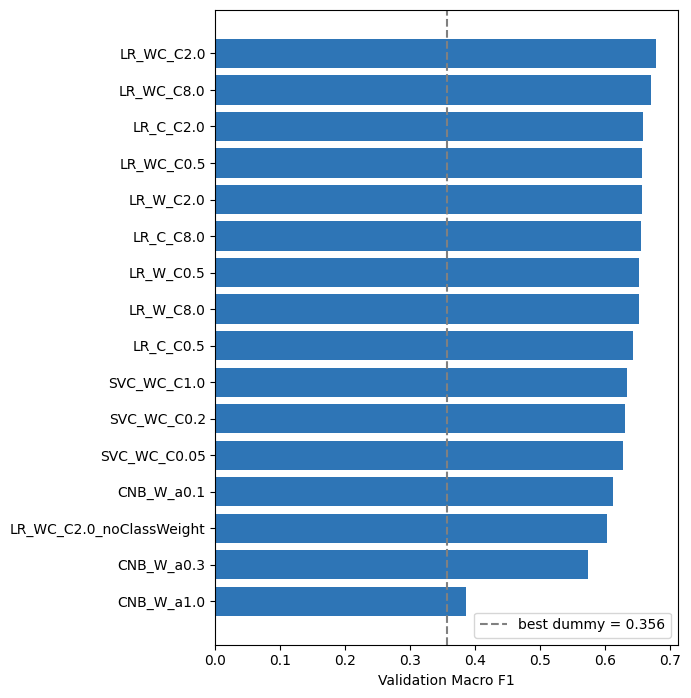

In [14]:
# Visual comparison on validation
plot_df = res_val[res_val["family"] != "Dummy"].sort_values("macro_f1")
fig, ax = plt.subplots(figsize=(7, 0.38 * len(plot_df) + 1))
ax.barh(plot_df["model"], plot_df["macro_f1"], color="#2E75B6")
dummy_best = res_val[res_val["family"] == "Dummy"]["macro_f1"].max()
ax.axvline(dummy_best, color="grey", ls="--", label=f"best dummy = {dummy_best:.3f}")
ax.set_xlabel("Validation Macro F1"); ax.legend(loc="lower right"); plt.tight_layout()
plt.savefig(OUT_DIR / "val_model_comparison.png", dpi=150); plt.show()

<div dir="rtl">

## ۱۰) آزمایش حذف فیلدهای متنی (Ablation)
آیا `advantages` و `disadvantages` واقعاً کمک می‌کنند؟ همان مدل (LR، ویژگی WC، همان `C`) را روی سه نسخه‌ی متن آموزش می‌دهیم.
(توجه: این فقط یک آزمایش تحلیلی روی val است؛ Split همان Split اصلی است.)
</div>


In [15]:
abl_rows = []
variants = {"body only": "text_body", "title + body": "text_title_body", "title + body + advantages + disadvantages (ours)": "text"}
for vname, vcol in variants.items():
    if vcol == "text":
        r = res_val[res_val["model"] == f"LR_WC_C{best_C}"].iloc[0]
        abl_rows.append({"text variant": vname, "macro_f1": r["macro_f1"], **{k: r[k] for k in [f"f1_{l}" for l in LABELS]}})
        continue
    f_, _ = fit_features(train[vcol], val[vcol], test[vcol], only_wc=True)
    clf = LogisticRegression(C=best_C, class_weight="balanced", max_iter=1000).fit(f_["WC"][0], y_tr)
    m = evaluate(y_va, clf.predict(f_["WC"][1]))
    abl_rows.append({"text variant": vname, "macro_f1": m["macro_f1"], **{k: m[k] for k in [f"f1_{l}" for l in LABELS]}})
abl = pd.DataFrame(abl_rows)
abl.to_csv(OUT_DIR / "ablation_text_fields_val.csv", index=False)
display(abl.round(4))

,text variant,macro_f1,f1_recommended,f1_not_recommended,f1_no_idea
0,body only,0.6281,0.9139,0.6356,0.3349
1,title + body,0.6690,0.9251,0.6838,0.3981
2,title + body + advantages + disadvantages (ours),0.6779,0.9308,0.6897,0.4131


<div dir="rtl">


## ۱۱) انتخاب مدل نهایی و تنظیم bias کلاس‌ها (فقط روی Val)
- مدل نهایی = بالاترین Macro F1 روی val (بین مدل‌های غیر Dummy).
- سپس یک عدد ثابت به امتیاز کلاس‌های `not_recommended` و `no_idea` اضافه می‌کنیم (نسبت به `recommended`) و روی val جست‌وجو می‌کنیم تا Macro F1 بیشتر شود.
- **قاعده‌ی از قبل مشخص:** bias فقط اگر روی val حداقل `0.002` بهبود بدهد پذیرفته می‌شود (برای جلوگیری از overfit به val).
</div>


In [16]:
cand = res_val[res_val["family"] != "Dummy"]
best_name = cand.iloc[0]["model"]
best = fitted[best_name]; best_clf, best_key = best["clf"], best["key"]
print(f"Selected on validation: {best_name}  (val Macro-F1 = {cand.iloc[0]['macro_f1']:.4f})")

S_va = get_scores_ordered(best_clf, feats[best_key][1])
scale = float(np.std(S_va)) or 1.0
grid = np.linspace(-1.0, 1.0, 21) * scale
base_f1 = macro_f1_int(y_va_i, S_va.argmax(1))

cands = []
for b1 in grid:
    for b2 in grid:
        bias = np.array([0.0, b1, b2])
        cands.append((macro_f1_int(y_va_i, (S_va + bias).argmax(1)), np.linalg.norm(bias), bias))
top = max(c[0] for c in cands)
near = [c for c in cands if c[0] >= top - 1e-4]
tuned_f1, _, bias_best = min(near, key=lambda c: c[1])        # among ties: smallest |bias|

ADOPT_BIAS = (tuned_f1 - base_f1) >= 0.002
bias_final = bias_best if ADOPT_BIAS else np.zeros(3)
print(f"val Macro-F1 raw = {base_f1:.4f} | with bias {np.round(bias_best, 3).tolist()} = {tuned_f1:.4f} -> adopt bias: {ADOPT_BIAS}")

Selected on validation: LR_WC_C2.0  (val Macro-F1 = 0.6779)
val Macro-F1 raw = 0.6779 | with bias [0.0, 0.0, 0.18] = 0.6798 -> adopt bias: False


<div dir="rtl">

## ۱۲) ارزیابی نهایی روی Test (فقط یک‌بار)
از این نقطه به بعد **هیچ تنظیمی** بر اساس نتایج test انجام نمی‌شود.
</div>


In [17]:
S_te = get_scores_ordered(best_clf, feats[best_key][2])
pred_raw_i = S_te.argmax(1)
pred_fin_i = (S_te + bias_final).argmax(1)
pred_raw = np.array(LABELS)[pred_raw_i]
pred_fin = np.array(LABELS)[pred_fin_i]

# Floors on test (for reference only)
dummy_rows = []
for nm in ["Dummy_most_frequent", "Dummy_stratified"]:
    dclf = fitted[nm]["clf"]
    dummy_rows.append({"model": nm, **evaluate(y_te, dclf.predict(feats["W"][2]))})

ci, boot = cluster_bootstrap_ci(y_te_i, pred_fin_i, test["product_id"].values, n_boot=N_BOOT)
final_metrics = evaluate(y_te, pred_fin)
rows = dummy_rows + [{"model": f"{best_name} (raw)", **evaluate(y_te, pred_raw)},
                     {"model": f"{best_name} + bias [FINAL]" if ADOPT_BIAS else f"{best_name} [FINAL]", **final_metrics}]
res_test = pd.DataFrame(rows)
res_test.to_csv(OUT_DIR / "results_test.csv", index=False)
display(res_test.round(4))
print(f"\nFINAL TEST Macro F1 = {final_metrics['macro_f1']:.4f}   95% CI (cluster bootstrap over products, n={N_BOOT}): [{ci[0]:.4f}, {ci[1]:.4f}]")
print("\n", classification_report(y_te, pred_fin, labels=LABELS, digits=3, zero_division=0))

,model,macro_f1,macro_precision,macro_recall,accuracy,balanced_acc,f1_recommended,f1_not_recommended,f1_no_idea
0,Dummy_most_frequent,0.2977,0.2690,0.3333,0.8071,0.3333,0.8932,0.0000,0.0000
1,Dummy_stratified,0.3482,0.3479,0.3489,0.6678,0.3489,0.8052,0.1040,0.1356
2,LR_WC_C2.0 (raw),0.6631,0.6445,0.6862,0.8516,0.6862,0.9344,0.6868,0.3682
3,LR_WC_C2.0 [FINAL],0.6631,0.6445,0.6862,0.8516,0.6862,0.9344,0.6868,0.3682



FINAL TEST Macro F1 = 0.6631   95% CI (cluster bootstrap over products, n=1000): [0.6281, 0.6973]

                  precision    recall  f1-score   support

    recommended      0.952     0.917     0.934       979
not_recommended      0.632     0.752     0.687       121
        no_idea      0.349     0.389     0.368       113

       accuracy                          0.852      1213
      macro avg      0.644     0.686     0.663      1213
   weighted avg      0.864     0.852     0.857      1213



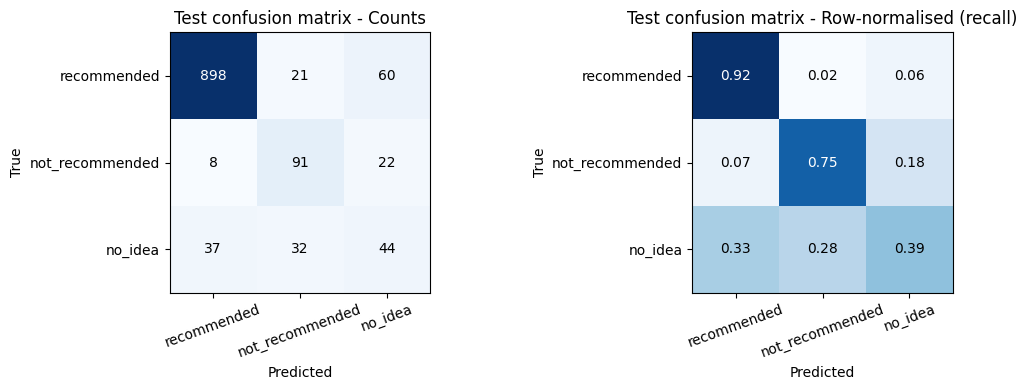

In [18]:
cm = confusion_matrix(y_te, pred_fin, labels=LABELS)
cm_norm = cm / cm.sum(1, keepdims=True)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, M, title, fmt in [(axes[0], cm, "Counts", "{:d}"), (axes[1], cm_norm, "Row-normalised (recall)", "{:.2f}")]:
    im = ax.imshow(M, cmap="Blues")
    ax.set_xticks(range(3)); ax.set_xticklabels(LABELS, rotation=20); ax.set_yticks(range(3)); ax.set_yticklabels(LABELS)
    ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title(f"Test confusion matrix - {title}")
    for i in range(3):
        for j in range(3):
            ax.text(j, i, fmt.format(M[i, j]), ha="center", va="center", color="white" if M[i, j] > M.max() * 0.6 else "black")
plt.tight_layout(); plt.savefig(OUT_DIR / "test_confusion_matrix.png", dpi=150); plt.show()

# save test predictions (needed for paired comparison with ParsBERT / FaBERT / XLM-R later)
pred_df = test[["id", "product_id", "label"]].rename(columns={"label": "y_true"}).copy()
pred_df["y_pred_raw"] = pred_raw; pred_df["y_pred_final"] = pred_fin
for i, l in enumerate(LABELS):
    pred_df[f"score_{l}"] = S_te[:, i]
pred_df.to_parquet(OUT_DIR / "test_predictions_baseline.parquet", index=False)

<div dir="rtl">

## ۱۳) تحلیل خطا (Failure Analysis)
این بخش برای گزارش و ارائه مهم‌ترین قسمت است: مدل کجا و چرا اشتباه می‌کند؟

Top positive-weighted word features per class:
</div>


In [19]:
# 1) Which words push each class? (only for linear models, word features)
clf = best_clf
if hasattr(clf, "coef_") or hasattr(clf, "feature_log_prob_"):
    W = clf.coef_ if hasattr(clf, "coef_") else clf.feature_log_prob_
    order = [list(clf.classes_).index(l) for l in LABELS]
    W = W[order]
    word_vec = vecs[best_key][0] if best_key in ("W", "WC") else None
    if word_vec is not None:
        names = np.array(word_vec.get_feature_names_out())
        n_word = len(names)
        top = {}
        for i, l in enumerate(LABELS):
            w = W[i, :n_word]
            top[l] = names[np.argsort(-w)[:25]]
        display(pd.DataFrame(top))
else:
    print("model has no linear weights; skipping")

,recommended,not_recommended,no_idea
0,عالی,اصلا,گرونه
1,خوب,بی,ولی
2,عالیه,بی کیفیت,نیستم
3,خوبه,نخرید,قیمت
4,مناسب,نمیکنم,خیلی ممنون
5,با کیفیت,افتضاح,پس
6,میکنم,حتی,تو
7,مزایا,مردم,رنگ رو
8,عالی بود,پیشنهاد نمیکنم,شرح
9,خوبی داره,دست,دقت


In [20]:
# 2) Error table on test
err = test[["id", "product_id", "label", "text", "rate", "n_words", "sub_category"]].copy()
err["pred"] = pred_fin
err["correct"] = err["label"] == err["pred"]
sc = S_te + bias_final
sc = sc - sc.max(1, keepdims=True)
prob = np.exp(sc) / np.exp(sc).sum(1, keepdims=True)
err["confidence"] = prob.max(1).round(3)
print("Overall test accuracy: %.4f | error rate: %.4f" % (err["correct"].mean(), 1 - err["correct"].mean()))

pairs = (err[~err["correct"]].groupby(["label", "pred"]).size().sort_values(ascending=False).to_frame("n_errors"))
display(pairs)

# 3) Error rate by rate / length / category
if err["rate"].notna().any():
    print("\nError rate by user rate:")
    display(err.groupby("rate")["correct"].agg(n="size", error_rate=lambda x: round(1 - x.mean(), 3)).T)

err["len_bucket"] = pd.cut(err["n_words"], [0, 2, 5, 10, 20, 50, 10_000], labels=["1-2", "3-5", "6-10", "11-20", "21-50", "50+"])
print("\nError rate by text length (words):")
display(err.groupby("len_bucket", observed=True)["correct"].agg(n="size", error_rate=lambda x: round(1 - x.mean(), 3)).T)

def macro_f1_present(g):
    labs = [l for l in LABELS if (g["label"] == l).any()]
    return f1_score(g["label"], g["pred"], labels=labs, average="macro", zero_division=0) if labs else np.nan
from sklearn.metrics import f1_score
cat = pd.DataFrame([{"sub_category": k, "n": len(g), "accuracy": g["correct"].mean(),
                     "macro_f1(present classes)": macro_f1_present(g)} for k, g in err.groupby("sub_category")]).set_index("sub_category")
print("\nBy sub_category (n >= 100):")
display(cat[cat["n"] >= 100].sort_values("n", ascending=False).round(3))

Overall test accuracy: 0.8516 | error rate: 0.1484


n_errors
label           pred                     
recommended     no_idea                60
no_idea         recommended            37
                not_recommended        32
not_recommended no_idea                22
recommended     not_recommended        21
not_recommended recommended             8


Error rate by user rate:


rate,0.25,1.00,1.20,1.40,1.55,1.65,1.70,1.75,2.00,2.10,2.15,2.30,2.40,2.50,2.60,2.70,2.75,2.80,2.85,2.90,2.95,3.00,3.05,3.10,3.20,3.25,3.30,3.35,3.40,3.50,3.60,3.65,3.70,3.75,3.80,3.90,4.00,4.05,4.10,4.20,4.25,4.30,4.40,4.45,4.50,4.60,4.65,4.70,4.75,4.80,4.85,4.90,5.00
n,3.000,79.000,2.0,1.0,1.0,1.0,2.0,1.0,22.000,2.0,1.0,2.0,2.0,3.000,1.0,1.0,6.000,4.00,1.0,1.0,1.0,139.000,1.0,1.0,2.0,5.0,1.0,2.0,9.000,9.000,9.0,1.0,2.0,4.00,4.00,1.0,191.000,1.0,2.0,20.0,12.0,3.000,13.000,1.0,16.0,12.0,4.0,4.0,9.0,10.0,1.0,2.0,442.000
error_rate,0.667,0.304,1.0,0.0,0.0,1.0,0.0,1.0,0.455,1.0,0.0,1.0,0.0,0.333,0.0,0.0,0.333,0.25,0.0,1.0,1.0,0.338,0.0,0.0,0.0,0.0,1.0,0.5,0.222,0.222,0.0,0.0,0.0,0.25,0.25,1.0,0.194,0.0,0.5,0.0,0.0,0.333,0.077,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.038



Error rate by text length (words):


len_bucket,1-2,3-5,6-10,11-20,21-50,50+
n,5.0,16.000,99.000,205.000,395.000,493.000
error_rate,0.0,0.062,0.051,0.122,0.122,0.205



By sub_category (n >= 100):


,n,accuracy,macro_f1(present classes)
sub_category,,,
beauty,430,0.865,0.677
clothe,286,0.836,0.692
toys and kids,215,0.884,0.695
book & stationary & art,194,0.897,0.651


In [21]:
# 4) Read real mistakes (the best material for the failure-analysis slide)
rng = np.random.default_rng(SEED)
for (t_lab, p_lab), n_err in pairs.head(4)["n_errors"].items():
    sub = err[(err["label"] == t_lab) & (err["pred"] == p_lab)]
    print(f"\n=== true = {t_lab}  |  predicted = {p_lab}   ({n_err} errors) ===")
    show = sub.sample(min(6, len(sub)), random_state=SEED)
    for _, r in show.iterrows():
        print(f"- [id={r['id']}] rate={r['rate']} conf={r['confidence']}  ->  {r['text'][:200]}")

err[~err["correct"]].sort_values("confidence", ascending=False).to_csv(OUT_DIR / "error_analysis_test.csv", index=False)
print("\nsaved all test errors (sorted by confidence) ->", OUT_DIR / "error_analysis_test.csv")


=== true = recommended  |  predicted = no_idea   (60 errors) ===
- [id=26256348] rate=nan conf=0.387  ->  یه اسباب بازی چینی . شارژرش داستان داره حسابی. عجیب‌ترین شارژری هست که دیدم. دو شاخه شارژ نداره. خیلی بد جا می‌افته تو دستگاه. . مزایا: بد نیست
- [id=34269376] rate=0.25 conf=0.446  ->  دقت کنید . من از اوپوس گرفتم و اصلی بود هر چند روش زده بود 1690 و من 1850 گرفتم فردای خرید من قیمتش رفت رو 2200 ویدیوی تشخیص اصلی و فرعیش رو میزارم در ضمن عکس های خود محصول، عکس از نمونه ی فیک هست
- [id=50241839] rate=5.0 conf=0.529  ->  تاب خواب . دوستان اول اینکه راحت شدم بعد خرید این تاب دوم‌اینکه فقط رخت خواب بزرگی که داخلشه 500 می ارزه و من میدونم قیمت اون بندای ابریشمی حداقل 200 تومنه پس این‌تابو واقعا دارن با کمترین سود ب دست‌م
- [id=34581532] rate=4.0 conf=0.944  ->  کیف چرم‌آرا . کیف کوچیک و جمع و جوریه. به ابعاد نوشته شده در مشخصات توجه کنید. سایز بند کیف قابل تغییر نیست. در کل با توجه به قیمت فروش ویژه‌ی دیجی‌کالا، خوبه و می‌ارزه.
- [id=8061748] rate=5.0 conf=0.432  ->  مرور کتاب . خب مو

<div dir="rtl">

## ۱۴) منحنی یادگیری
با ۱۰٪ / ۲۵٪ / ۵۰٪ / ۱۰۰٪ محصولات train، همان مدل را آموزش می‌دهیم. اگر منحنی هنوز رو به بالاست، یعنی داده‌ی بیشتر (یا مدل قوی‌تر) کمک می‌کند. (ویژگی‌ها از vocabulary کل train ساخته شده‌اند.)
</div>


,train_fraction,n_train,val_macro_f1
0,0.10,593,0.5183
1,0.25,1487,0.5867
2,0.50,2891,0.6417
3,1.00,5722,0.6779


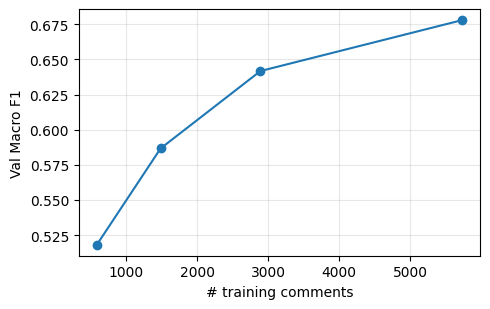

In [22]:
if RUN_LEARNING_CURVE and not QUICK:
    rng = np.random.default_rng(SEED)
    pids = train["product_id"].unique(); rng.shuffle(pids)
    Xtr_full = feats[best_key][0]; Xva_full = feats[best_key][1]
    lc = []
    for frac in [0.1, 0.25, 0.5, 1.0]:
        sel = set(pids[: max(1, int(len(pids) * frac))])
        mask = train["product_id"].isin(sel).values
        m = clone(best_clf).fit(Xtr_full[mask], y_tr[mask])
        pr = m.predict(Xva_full)
        lc.append({"train_fraction": frac, "n_train": int(mask.sum()), "val_macro_f1": evaluate(y_va, pr)["macro_f1"]})
    lc = pd.DataFrame(lc); display(lc.round(4)); lc.to_csv(OUT_DIR / "learning_curve_val.csv", index=False)
    plt.figure(figsize=(5, 3.2)); plt.plot(lc["n_train"], lc["val_macro_f1"], marker="o")
    plt.xlabel("# training comments"); plt.ylabel("Val Macro F1"); plt.grid(alpha=.3); plt.tight_layout()
    plt.savefig(OUT_DIR / "learning_curve.png", dpi=150); plt.show()
else:
    print("skipped")

<div dir="rtl">

## ۱۵) ذخیره‌ی مدل و ساخت تابع `predict_recommendation(text)`
این همان تابعی است که در قرارداد پروژه تعریف کردیم. بعد از ذخیره، یک **تست سازگاری** انجام می‌شود: پیش‌بینی تابع باید دقیقاً با پیش‌بینی نوت‌بوک یکی باشد.

</div>


In [23]:
bundle = {"vectorizers": vecs[best_key], "clf": best_clf, "bias": bias_final, "labels": LABELS,
          "feature_key": best_key, "model_name": best_name}
joblib.dump(bundle, MODEL_DIR / "baseline_bundle.joblib")

PREDICTOR_SRC = r'''
from pathlib import Path

import joblib
import numpy as np
from scipy.sparse import hstack

from persian_text import LABELS, clean_text  # noqa: F401  (tfidf_preprocess is needed to unpickle the vectorizers)
import persian_text  # noqa: F401

_DEFAULT = Path(__file__).resolve().parent.parent / "models" / "baseline_bundle.joblib"
_CACHE = {}


def _load(path=None):
    path = str(path or _DEFAULT)
    if path not in _CACHE:
        _CACHE[path] = joblib.load(path)
    return _CACHE[path]


def _scores(clf, X):
    s = clf.decision_function(X) if hasattr(clf, "decision_function") else clf.predict_log_proba(X)
    order = [list(clf.classes_).index(l) for l in LABELS]
    return s[:, order]


def predict_recommendation_batch(texts, model_path=None):
    b = _load(model_path)
    cleaned = [clean_text(t) for t in texts]
    mats = [v.transform(cleaned) for v in b["vectorizers"]]
    X = mats[0] if len(mats) == 1 else hstack(mats).tocsr()
    idx = (_scores(b["clf"], X) + b["bias"]).argmax(1)
    return [LABELS[i] for i in idx]


def predict_recommendation(text, model_path=None):
    return predict_recommendation_batch([text], model_path)[0]
'''
(SRC_DIR / "baseline_predictor.py").write_text(PREDICTOR_SRC, encoding="utf-8")

import baseline_predictor
importlib.reload(baseline_predictor)
from baseline_predictor import predict_recommendation, predict_recommendation_batch

# ---- consistency test: module output must equal the notebook output
sample_idx = np.random.default_rng(SEED).choice(len(test), size=min(300, len(test)), replace=False)
mod_pred = predict_recommendation_batch(test["text"].iloc[sample_idx].tolist(), MODEL_DIR / "baseline_bundle.joblib")
assert list(mod_pred) == list(pred_fin[sample_idx]), "predictor module disagrees with notebook predictions!"
print("consistency test passed on", len(sample_idx), "test comments")

for t in ["عالی بود، کیفیتش فوق‌العاده‌ست و پیشنهاد می‌کنم", "افتضاح بود، اصلا نخرید پولتون هدر میره", "نمیدونم والا، معمولی بود"]:
    print(f"{predict_recommendation(t, MODEL_DIR / 'baseline_bundle.joblib'):>16}  <-  {t}")

consistency test passed on 300 test comments
     recommended  <-  عالی بود، کیفیتش فوق‌العاده‌ست و پیشنهاد می‌کنم
 not_recommended  <-  افتضاح بود، اصلا نخرید پولتون هدر میره
         no_idea  <-  نمیدونم والا، معمولی بود


<div dir="rtl">

## ۱۶) خلاصه‌ی نهایی:

</div>


In [24]:
summary = {
    "n_comments_after_cleaning": int(len(df)),
    "split_rows": {s: int((df.split == s).sum()) for s in ("train", "val", "test")},
    "split_products": {s: int(df.loc[df.split == s, "product_id"].nunique()) for s in ("train", "val", "test")},
    "selected_model": best_name, "features": best_key, "bias_adopted": bool(ADOPT_BIAS), "bias": [round(float(b), 4) for b in bias_final],
    "val_macro_f1_selected": float(cand.iloc[0]["macro_f1"]),
    "test_macro_f1": float(final_metrics["macro_f1"]), "test_macro_f1_ci95": [float(ci[0]), float(ci[1])],
    "test_f1_per_class": {l: float(final_metrics[f"f1_{l}"]) for l in LABELS},
    "best_dummy_test_macro_f1": float(max(r["macro_f1"] for r in dummy_rows)),
    "files": {"split": str(SPLIT_DIR / "data_split.parquet"), "model": str(MODEL_DIR / "baseline_bundle.joblib"),
              "predictor": str(SRC_DIR / "baseline_predictor.py"), "text_utils": str(SRC_DIR / "persian_text.py"),
              "test_predictions": str(OUT_DIR / "test_predictions_baseline.parquet")},
}
json.dump(summary, open(OUT_DIR / "summary.json", "w"), ensure_ascii=False, indent=2)
print(json.dumps(summary, ensure_ascii=False, indent=2))
print("\nAll outputs are in:", WORK_DIR.resolve())

{
  "n_comments_after_cleaning": 7988,
  "split_rows": {
    "train": 5722,
    "val": 1053,
    "test": 1213
  },
  "split_products": {
    "train": 3709,
    "val": 738,
    "test": 753
  },
  "selected_model": "LR_WC_C2.0",
  "features": "WC",
  "bias_adopted": false,
  "bias": [
    0.0,
    0.0,
    0.0
  ],
  "val_macro_f1_selected": 0.6778551039862228,
  "test_macro_f1": 0.6631455259638959,
  "test_macro_f1_ci95": [
    0.6281413896474537,
    0.6972982859437918
  ],
  "test_f1_per_class": {
    "recommended": 0.9344432882414152,
    "not_recommended": 0.6867924528301886,
    "no_idea": 0.3682008368200837
  },
  "best_dummy_test_macro_f1": 0.3482492865047469,
  "files": {
    "split": "/content/drive/MyDrive/QBC13_final/baseline/splits/data_split.parquet",
    "model": "/content/drive/MyDrive/QBC13_final/baseline/models/baseline_bundle.joblib",
    "predictor": "/content/drive/MyDrive/QBC13_final/baseline/src/baseline_predictor.py",
    "text_utils": "/content/drive/MyDrive/QBC1